# Métricas de regresión: explicación paso a paso

Este notebook explica, con ejemplos sencillos, las métricas más habituales para evaluar modelos de **regresión**.

La idea principal es esta:

> En regresión no basta con decir si el modelo “acierta” o “falla”. Tenemos que medir **cuánto se equivoca**.

Veremos:

- **Bias / Mean Error** → sesgo medio del modelo.
- **MAE / Mean Absolute Error** → EAM, error absoluto medio.
- **MSE / Mean Squared Error** → ECM, error cuadrático medio.
- **RMSE / Root Mean Squared Error** → raíz del error cuadrático medio.
- **MAPE / Mean Absolute Percentage Error** → EPAM, error porcentual absoluto medio.
- **R² / Coefficient of Determination** → coeficiente de determinación.
- **Adjusted R² / Adjusted Coefficient of Determination** → R² ajustado.
- Otros conceptos necesarios: **residual**, **baseline model**, **underfitting**, **overfitting** y comparación train/test.

## 1. Idea base: valor real, predicción y error

En un problema de regresión tenemos:

- Un valor real:

$$
y_i
$$

- Una predicción del modelo:

$$
\hat{y}_i
$$

- Un error de predicción.

En este notebook usaremos esta convención:

$$
e_i = \hat{y}_i - y_i
$$

Es decir:

$$
\text{error} = \text{predicción} - \text{valor real}
$$

Con esta convención:

- Si el error es positivo, el modelo **predice de más**.
- Si el error es negativo, el modelo **predice de menos**.
- Si el error es cero, el modelo ha acertado exactamente.

En algunos libros verás el residuo definido al revés:

$$
r_i = y_i - \hat{y}_i
$$

No pasa nada. Para métricas como MAE, MSE o RMSE el signo no cambia el resultado porque usamos valor absoluto o cuadrados. Pero para el **sesgo** sí importa dejar clara la convención.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Para que los números se vean con pocos decimales en tablas
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 2. Un ejemplo mínimo

Imagina que queremos predecir el precio de varios pisos en miles de euros.

Por ejemplo:

- Valor real: 200 significa 200.000 €.
- Predicción: 190 significa 190.000 €.

Vamos a crear una tabla muy pequeña para entenderlo a mano.

In [2]:
y_real = np.array([100, 150, 200, 250, 300], dtype=float)
y_pred = np.array([110, 140, 210, 240, 330], dtype=float)

errors = y_pred - y_real
abs_errors = np.abs(errors)
squared_errors = errors ** 2
percentage_abs_errors = np.abs(errors / y_real) * 100

df = pd.DataFrame({
    "y_real": y_real,
    "y_pred": y_pred,
    "error = y_pred - y_real": errors,
    "absolute_error": abs_errors,
    "squared_error": squared_errors,
    "absolute_percentage_error_%": percentage_abs_errors
})

df

,y_real,y_pred,error = y_pred - y_real,absolute_error,squared_error,absolute_percentage_error_%
0,100.000,110.000,10.000,10.000,100.000,10.000
1,150.000,140.000,-10.000,10.000,100.000,6.667
2,200.000,210.000,10.000,10.000,100.000,5.000
3,250.000,240.000,-10.000,10.000,100.000,4.000
4,300.000,330.000,30.000,30.000,900.000,10.000


## 3. Bias / Mean Error

En español podemos llamarlo **sesgo medio** o **error medio**.

En inglés suele aparecer como:

- **Bias**
- **Mean Error**
- **ME**

La fórmula, usando nuestra convención, es:

$$
ME = \frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i - y_i)
$$

### ¿Qué mide?

Mide si el modelo tiende a equivocarse sistemáticamente hacia arriba o hacia abajo.

Con nuestra convención:

- **ME > 0** → el modelo tiende a predecir de más.
- **ME < 0** → el modelo tiende a predecir de menos.
- **ME = 0** → no hay sesgo medio aparente.

### Cuidado importante

Un sesgo cercano a cero **no significa necesariamente que el modelo sea bueno**.

Puede ocurrir que unos errores positivos y otros negativos se compensen.

In [29]:
mean_error = np.mean(errors)
mean_error

np.float64(6.0)

En este ejemplo, el sesgo medio se calcula sumando todos los errores y dividiendo entre el número de observaciones.

In [30]:
print("Errores:", errors)
print("Suma de errores:", errors.sum())
print("Número de observaciones:", len(errors))
print("Bias / Mean Error:", errors.sum() / len(errors))

Errores: [ 10. -10.  10. -10.  30.]
Suma de errores: 30.0
Número de observaciones: 5
Bias / Mean Error: 6.0


## 4. MAE / Mean Absolute Error / EAM

En español: **Error Absoluto Medio**.

En inglés:

- **MAE**
- **Mean Absolute Error**

La fórmula es:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i|
$$

Como usamos valor absoluto, ya no importa si el modelo predijo de más o de menos. Solo importa la magnitud del error.

### ¿Qué mide?

Mide el error medio en las mismas unidades que la variable objetivo.

Si estamos prediciendo precios en miles de euros, entonces:

$$
MAE = 14
$$

significaría que el modelo se equivoca, de media, en unos 14.000 €.

### ¿Para qué se usa?

Se usa cuando queremos una métrica fácil de interpretar.

MAE responde a esta pregunta:

> De media, ¿cuánto se equivoca mi modelo?

In [5]:
display(y_real - y_pred)
display(np.abs(y_real - y_pred))
display(np.mean(np.abs(y_real - y_pred)))


array([-10.,  10., -10.,  10., -30.])

array([10., 10., 10., 10., 30.])

np.float64(14.0)

In [6]:
mae = np.mean(np.abs(y_real - y_pred))
mae

np.float64(14.0)

## 5. MSE / Mean Squared Error / ECM

En español: **Error Cuadrático Medio**.

En inglés:

- **MSE**
- **Mean Squared Error**

La fórmula es:

$$
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2
$$

### ¿Qué mide?

Mide el error medio al cuadrado.

La clave está en el cuadrado:

- Un error de 10 se convierte en 100.
- Un error de 20 se convierte en 400.
- Un error de 50 se convierte en 2.500.

Por tanto, el MSE castiga mucho más los errores grandes.

### Problema de interpretación

Si la variable objetivo está en miles de euros, el MSE está en “miles de euros al cuadrado”.

Eso no es muy intuitivo.

Por eso aparece RMSE.

In [7]:
mse = np.mean((y_real - y_pred) ** 2)
mse

np.float64(260.0)

## 6. RMSE / Root Mean Squared Error

En español: **Raíz del Error Cuadrático Medio**.

En inglés:

- **RMSE**
- **Root Mean Squared Error**

La fórmula es:

$$
RMSE = \sqrt{MSE}
$$

O directamente:

$$
RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}
$$

### ¿Qué mide?

Mide el error típico del modelo, pero penalizando más los errores grandes que MAE.

### ¿Cómo se interpreta?

Vuelve a estar en las mismas unidades que la variable objetivo.

Si estamos prediciendo precios en miles de euros y:

$$
RMSE = 20
$$

podemos decir que el error típico del modelo está alrededor de 20.000 €, con más castigo a los errores grandes.

### Diferencia intuitiva entre MAE y RMSE

- **MAE**: error medio fácil de explicar.
- **RMSE**: error medio con castigo extra a errores grandes.

**RMSE siempre es mayor o igual que MAE.**

<mark>Si RMSE es bastante mayor que MAE, suele indicar que hay algunos errores especialmente grandes.<mark>

Peroooooo....

Para comparar ambas métricas no conviene mirar la diferencia absoluta, porque depende de las unidades del problema. Es más útil mirar el cociente:

$$
\frac{RMSE}{MAE}
$$

Si el cociente está cerca de 1, los errores suelen ser bastante homogéneos.

Si el cociente empieza a alejarse de 1, por ejemplo por encima de 1.3 o 1.5, significa que algunos errores grandes están influyendo bastante en el RMSE.

Por tanto, RMSE no solo nos dice el tamaño medio del error, sino también si existen errores especialmente grandes que el MAE suaviza más.

<mark>Si RMSE es bastante mayor que MAE, suele indicar que hay algunos errores especialmente grandes.<mark>

MAE responde:
> "¿Cuánto me equivoco de media?"

RMSE responde:
> "¿Cuánto me equivoco de media, penalizando mucho más los errores grandes?"

RMSE / MAE responde:
> "¿Hay errores grandes que están distorsionando el promedio?"

In [8]:
rmse = np.sqrt(mse)
rmse

np.float64(16.1245154965971)

## 7. MAPE / Mean Absolute Percentage Error / EPAM

En español: **Error Porcentual Absoluto Medio**.

En inglés:

- **MAPE**
- **Mean Absolute Percentage Error**

También puedes verlo en español como **EPAM**.

La fórmula es:

$$
MAPE = \frac{100}{n}\sum_{i=1}^{n}\left|\frac{y_i - \hat{y}_i}{y_i}\right|
$$

### ¿Qué mide?

Mide el error medio en porcentaje.

Por ejemplo:

$$
MAPE = 8\%
$$

significa que el modelo se equivoca, de media, alrededor de un 8% respecto al valor real.

### ¿Para qué se usa?

Es útil cuando quieres explicar el error de forma proporcional.

Por ejemplo, no es lo mismo equivocarte 10.000 € en una vivienda de 100.000 € que en una de 1.000.000 €.

### Cuidado importante

<mark>MAPE falla o se vuelve muy inestable cuando los valores reales son cero o muy cercanos a cero, porque divide entre el valor real.</mark>

In [9]:
mape = np.mean(np.abs((y_real - y_pred) / y_real)) * 100
mape

np.float64(7.133333333333333)

## 8. R² / Coefficient of Determination

En español: **coeficiente de determinación**.

En inglés:

- **R-squared**
- **R²**
- **Coefficient of Determination**

La fórmula es:

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

Donde:

$$
\bar{y}
$$

es la media de los valores reales.

### ¿Qué compara R²?

R² compara dos cosas:

1. El error de tu modelo.
2. El error de un modelo muy tonto que siempre predice la media.

Ese modelo básico se llama:

- **Baseline model**
- **Mean model**
- Modelo de referencia

### Interpretación habitual

- **R² = 1** → predicción perfecta.
- **R² = 0** → el modelo no mejora a predecir siempre la media.
- **R² < 0** → el modelo es peor que predecir siempre la media.

<mark><strong>R² oscila como máximo hasta 1, pero por abajo no tiene un límite fijo.</strong></mark>

Un valor como:

$$
R^2 = 0.82
$$

suele interpretarse como:

> El modelo explica aproximadamente el 82% de la variabilidad de la variable objetivo.

Pero esta frase hay que usarla con cuidado. R² no mide por sí solo si el modelo generaliza bien. Para eso necesitamos comparar entrenamiento y test.

In [10]:
ss_res = np.sum((y_real - y_pred) ** 2)          # suma de errores cuadrados del modelo
ss_tot = np.sum((y_real - np.mean(y_real)) ** 2) # suma de errores cuadrados usando la media
r2 = 1 - ss_res / ss_tot

print("SS_residual:", ss_res)
print("SS_total:", ss_tot)
print("R²:", r2)

SS_residual: 1300.0
SS_total: 25000.0
R²: 0.948


R² es una métrica útil para saber cuánto mejora nuestro modelo respecto a una predicción básica, como predecir siempre la media de la variable objetivo.

Sin embargo, hay que usarlo con cuidado: un R² alto en entrenamiento no garantiza que el modelo generalice bien. El modelo puede haber aprendido demasiado bien los datos de entrenamiento y funcionar peor con datos nuevos.

Por eso, la práctica correcta es calcular R² y otras métricas de error tanto en entrenamiento como en test.

* Si el rendimiento en entrenamiento y test es parecido, el modelo probablemente generaliza razonablemente bien.
* Si el rendimiento en entrenamiento es muy bueno pero en test cae mucho, probablemente hay sobreajuste.
* Si el rendimiento es malo en ambos conjuntos, probablemente el modelo es demasiado simple o las variables no explican bien el fenómeno.

## 9. Una función para calcular todas las métricas

Vamos a crear una función propia, sin depender de librerías externas, para entender exactamente qué se está calculando.

In [31]:
def regression_metrics(y_true, y_pred, p=None):
    """
    Calcula métricas básicas de regresión.

    Parámetros
    ----------
    y_true : array-like
        Valores reales.
    y_pred : array-like
        Valores predichos.
    p : int, opcional
        Número de variables predictoras. Solo se usa para Adjusted R².
    """
    y_true = np.array(y_true, dtype=float)
    y_pred = np.array(y_pred, dtype=float)
    n = len(y_true)

    error = y_pred - y_true
    mae = np.mean(np.abs(error))
    mse = np.mean(error ** 2)
    rmse = np.sqrt(mse)

    # MAPE: cuidado si hay ceros en y_true
    if np.any(y_true == 0):
        mape = np.nan
    else:
        mape = np.mean(np.abs(error / y_true)) * 100

    bias = np.mean(error)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - ss_res / ss_tot

    results = {
        "Bias / Mean Error": bias,
        "MAE / EAM": mae,
        "MSE / ECM": mse,
        "RMSE": rmse,
        "MAPE / EPAM (%)": mape,
        "R²": r2,
    }

    if p is not None:
        if n > p + 1:
            adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
        else:
            adjusted_r2 = np.nan
        results["Adjusted R²"] = adjusted_r2

    return pd.Series(results)

regression_metrics(y_real, y_pred, p=1)

Bias / Mean Error     6.000
MAE / EAM            14.000
MSE / ECM           260.000
RMSE                 16.125
MAPE / EPAM (%)       7.133
R²                    0.948
Adjusted R²           0.931
dtype: float64

## 10. Por qué el sesgo no basta

Ahora vamos a crear dos modelos ficticios.

Ambos pueden tener un sesgo medio parecido, pero uno puede equivocarse mucho más que el otro.

Esto es importante porque el sesgo puede esconder errores que se compensan.

In [12]:
y_real_2 = np.array([100, 100, 100, 100], dtype=float)

# Modelo A: se equivoca poco y de forma equilibrada
pred_model_a = np.array([95, 105, 98, 102], dtype=float)

# Modelo B: se equivoca muchísimo, pero los errores se compensan
pred_model_b = np.array([50, 150, 40, 160], dtype=float)

comparison = pd.DataFrame({
    "Real": y_real_2,
    "Model A prediction": pred_model_a,
    "Model A error": pred_model_a - y_real_2,
    "Model B prediction": pred_model_b,
    "Model B error": pred_model_b - y_real_2,
})

comparison

,Real,Model A prediction,Model A error,Model B prediction,Model B error
0,100.000,95.000,-5.000,50.000,-50.000
1,100.000,105.000,5.000,150.000,50.000
2,100.000,98.000,-2.000,40.000,-60.000
3,100.000,102.000,2.000,160.000,60.000


In [13]:
metrics_a = regression_metrics(y_real_2, pred_model_a)
metrics_b = regression_metrics(y_real_2, pred_model_b)

pd.DataFrame({
    "Model A": metrics_a,
    "Model B": metrics_b
})

/tmp/ipykernel_370/1953773560.py:32: RuntimeWarning: divide by zero encountered in scalar divide
  r2 = 1 - ss_res / ss_tot


,Model A,Model B
Bias / Mean Error,0.000,0.000
MAE / EAM,3.500,55.000
MSE / ECM,14.500,"3,050.000"
RMSE,3.808,55.227
MAPE / EPAM (%),3.500,55.000
R²,-inf,-inf


Observa la idea:

- El sesgo puede ser cercano a cero.
- Pero MAE, MSE y RMSE pueden ser muy diferentes.

Por eso no conviene evaluar un modelo solo con el sesgo.

## 11. Ejemplo con una regresión lineal sencilla

Ahora vamos a simular un problema clásico:

> Queremos predecir el precio de una vivienda a partir de sus metros cuadrados.

La variable de entrada será:

$$
x = \text{metros cuadrados}
$$

La variable objetivo será:

$$
y = \text{precio en miles de euros}
$$

Crearemos datos con una relación aproximadamente lineal.

In [14]:
np.random.seed(7)

m2 = np.array([45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100, 110, 120], dtype=float)
precio_real = 30 + 2.4 * m2 + np.random.normal(0, 12, size=len(m2))

housing = pd.DataFrame({
    "m2": m2,
    "precio_real_k€": precio_real
})

housing

,m2,precio_real_k€
0,45.000,158.286
1,50.000,144.409
2,55.000,162.394
3,60.000,178.890
4,65.000,176.533
5,70.000,198.025
6,75.000,209.989
7,80.000,200.943
8,85.000,246.212
9,90.000,253.206


Ajustamos una recta usando `numpy.polyfit`.

No hace falta todavía saber todos los detalles matemáticos de `polyfit`.

La idea es que buscamos una recta de esta forma:

$$
\hat{y} = b_0 + b_1x
$$

Donde:

- $$b_0$$ es el intercepto.
- $$b_1$$ es la pendiente.

In [15]:
# Ajuste de una recta: precio = pendiente * m2 + intercepto
pendiente, intercepto = np.polyfit(m2, precio_real, deg=1)

precio_pred = pendiente * m2 + intercepto

print("Pendiente:", pendiente)
print("Intercepto:", intercepto)

Pendiente: 2.330211438582081
Intercepto: 35.64416543492543


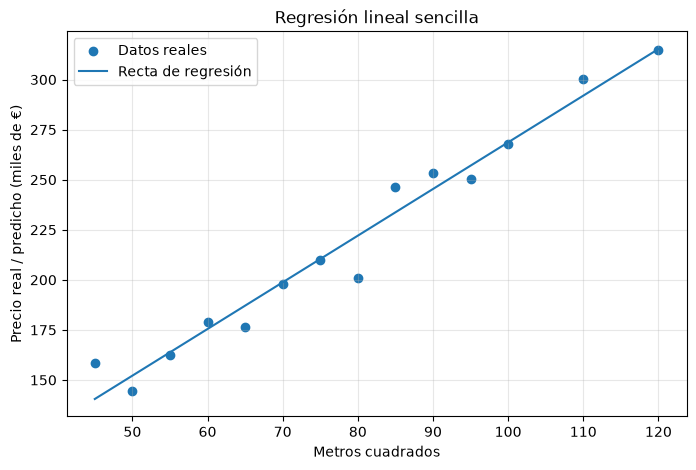

In [16]:
plt.figure(figsize=(8, 5))
plt.scatter(m2, precio_real, label="Datos reales")
plt.plot(m2, precio_pred, label="Recta de regresión")
plt.xlabel("Metros cuadrados")
plt.ylabel("Precio real / predicho (miles de €)")
plt.title("Regresión lineal sencilla")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 12. Visualizar los errores

Cada distancia vertical entre un punto real y la recta es un error.

En este gráfico, las líneas verticales representan los errores del modelo.

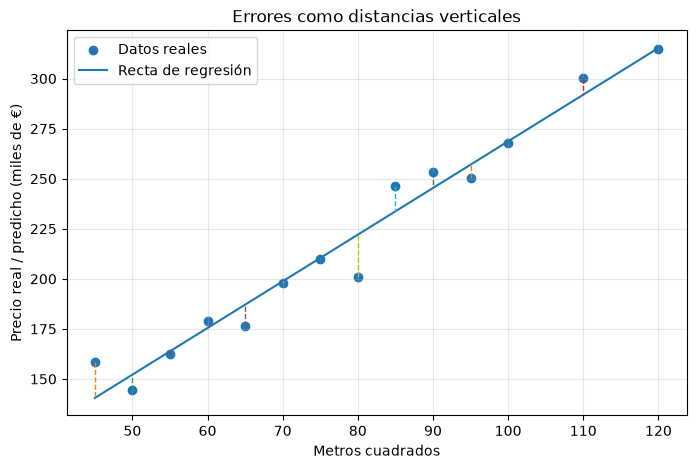

In [17]:
plt.figure(figsize=(8, 5))
plt.scatter(m2, precio_real, label="Datos reales")
plt.plot(m2, precio_pred, label="Recta de regresión")

for x_i, y_i, yhat_i in zip(m2, precio_real, precio_pred):
    plt.plot([x_i, x_i], [y_i, yhat_i], linestyle="--", linewidth=1)

plt.xlabel("Metros cuadrados")
plt.ylabel("Precio real / predicho (miles de €)")
plt.title("Errores como distancias verticales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [18]:
housing_errors = housing.copy()
housing_errors["precio_pred_k€"] = precio_pred
housing_errors["error_pred_minus_real"] = precio_pred - precio_real
housing_errors["absolute_error"] = np.abs(precio_pred - precio_real)
housing_errors["squared_error"] = (precio_pred - precio_real) ** 2
housing_errors["absolute_percentage_error_%"] = np.abs((precio_pred - precio_real) / precio_real) * 100

housing_errors

,m2,precio_real_k€,precio_pred_k€,error_pred_minus_real,absolute_error,squared_error,absolute_percentage_error_%
0,45.000,158.286,140.504,-17.783,17.783,316.222,11.234
1,50.000,144.409,152.155,7.746,7.746,60.000,5.364
2,55.000,162.394,163.806,1.412,1.412,1.994,0.869
3,60.000,178.890,175.457,-3.433,3.433,11.788,1.919
4,65.000,176.533,187.108,10.575,10.575,111.830,5.990
5,70.000,198.025,198.759,0.734,0.734,0.539,0.371
6,75.000,209.989,210.410,0.421,0.421,0.177,0.200
7,80.000,200.943,222.061,21.118,21.118,445.960,10.509
8,85.000,246.212,233.712,-12.500,12.500,156.244,5.077
9,90.000,253.206,245.363,-7.843,7.843,61.509,3.097


Calculamos las métricas del modelo.

In [19]:
regression_metrics(precio_real, precio_pred, p=1)

Bias / Mean Error   -0.000
MAE / EAM            7.094
MSE / ECM           91.072
RMSE                 9.543
MAPE / EPAM (%)      3.595
R²                   0.966
Adjusted R²          0.963
dtype: float64

## 13. Interpretación de las métricas del ejemplo

Supongamos que obtenemos algo parecido a esto:

- **MAE / EAM = 7.5**
- **RMSE = 9.5**
- **MAPE / EPAM = 3.8%**
- **R² = 0.96**

Como los precios están en miles de euros, podemos interpretar:

- El modelo se equivoca de media unos 7.500 € según MAE.
- El error típico penalizando más los errores grandes es de unos 9.500 € según RMSE.
- El error porcentual medio está cerca del 3.8% según MAPE.
- El modelo explica gran parte de la variabilidad de los precios según R².

La lectura correcta no es elegir una sola métrica y olvidarse de las demás.

Lo correcto es mirar varias métricas juntas.

## 14. Comparar varios modelos

Vamos a comparar tres modelos:

1. **Mean baseline**: siempre predice la media.
2. **Linear regression**: la recta que hemos ajustado.
3. **Bad model**: una recta desplazada artificialmente hacia arriba.

Esto ayuda a entender para qué sirven las métricas.

In [20]:
pred_mean_baseline = np.full_like(precio_real, fill_value=np.mean(precio_real))
pred_linear = precio_pred
pred_bad = precio_pred + 35

models = {
    "Mean baseline": pred_mean_baseline,
    "Linear regression": pred_linear,
    "Bad shifted model": pred_bad,
}

metrics_table = pd.DataFrame({
    name: regression_metrics(precio_real, pred, p=1)
    for name, pred in models.items()
}).T

metrics_table

,Bias / Mean Error,MAE / EAM,MSE / ECM,RMSE,MAPE / EPAM (%),R²,Adjusted R²
Mean baseline,-0.000,45.770,"2,697.971",51.942,21.961,0.000,-0.083
Linear regression,-0.000,7.094,91.072,9.543,3.595,0.966,0.963
Bad shifted model,35.000,35.000,"1,316.072",36.278,17.085,0.512,0.472


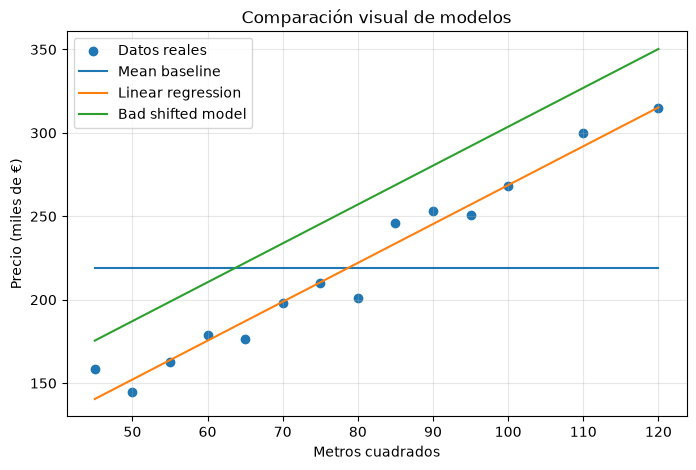

In [21]:
plt.figure(figsize=(8, 5))
plt.scatter(m2, precio_real, label="Datos reales")
plt.plot(m2, pred_mean_baseline, label="Mean baseline")
plt.plot(m2, pred_linear, label="Linear regression")
plt.plot(m2, pred_bad, label="Bad shifted model")
plt.xlabel("Metros cuadrados")
plt.ylabel("Precio (miles de €)")
plt.title("Comparación visual de modelos")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Qué deberías observar

El **Mean baseline** no usa realmente los metros cuadrados. Siempre predice lo mismo.

La **Linear regression** debería mejorar claramente al baseline.

El **Bad shifted model** puede tener una forma parecida a la recta buena, pero está desplazado. Por eso su **Bias / Mean Error** debería ser positivo y grande.

## 15. R² explicado contra el baseline

R² compara el error de tu modelo contra el error de predecir siempre la media.

Primero calculamos:

$$
SS_{res} = \sum_{i=1}^{n}(y_i - \hat{y}_i)^2
$$

Esto es el error cuadrático total de tu modelo.

Después calculamos:

$$
SS_{tot} = \sum_{i=1}^{n}(y_i - \bar{y})^2
$$

Esto es el error cuadrático total del baseline que siempre predice la media.

Finalmente:

$$
R^2 = 1 - \frac{SS_{res}}{SS_{tot}}
$$

Si tu modelo tiene mucho menos error que el baseline, el cociente será pequeño y R² se acercará a 1.

Si tu modelo tiene el mismo error que el baseline, R² será cercano a 0.

Si tu modelo tiene más error que el baseline, R² será negativo.

In [22]:
def r2_details(y_true, y_pred):
    y_true = np.array(y_true, dtype=float)
    y_pred = np.array(y_pred, dtype=float)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return pd.Series({
        "SS_residual_model": ss_res,
        "SS_total_baseline_mean": ss_tot,
        "SS_res / SS_tot": ss_res / ss_tot,
        "R²": 1 - ss_res / ss_tot,
    })

pd.DataFrame({
    name: r2_details(precio_real, pred)
    for name, pred in models.items()
}).T

,SS_residual_model,SS_total_baseline_mean,SS_res / SS_tot,R²
Mean baseline,"37,771.589","37,771.589",1.000,0.000
Linear regression,"1,275.003","37,771.589",0.034,0.966
Bad shifted model,"18,425.003","37,771.589",0.488,0.512


## 16. MAPE / EPAM cuando hay valores cercanos a cero

MAPE divide entre el valor real.

Por eso puede explotar cuando el valor real es cero o muy pequeño.

Ejemplo:

- Valor real: 1
- Predicción: 2
- Error absoluto: 1
- Error porcentual: 100%

Pero si:

- Valor real: 100
- Predicción: 101
- Error absoluto: 1
- Error porcentual: 1%

El error absoluto es el mismo, pero el porcentaje cambia muchísimo.

In [23]:
y_small = np.array([1, 10, 100], dtype=float)
y_small_pred = np.array([2, 11, 101], dtype=float)

pd.DataFrame({
    "y_real": y_small,
    "y_pred": y_small_pred,
    "absolute_error": np.abs(y_small_pred - y_small),
    "absolute_percentage_error_%": np.abs((y_small_pred - y_small) / y_small) * 100,
})

,y_real,y_pred,absolute_error,absolute_percentage_error_%
0,1.000,2.000,1.000,100.000
1,10.000,11.000,1.000,10.000
2,100.000,101.000,1.000,1.000


### Alternativa útil: WAPE / Weighted Absolute Percentage Error

Una alternativa al MAPE es WAPE.

En inglés:

- **WAPE**
- **Weighted Absolute Percentage Error**

La fórmula es:

$$
WAPE = \frac{\sum_{i=1}^{n}|y_i - \hat{y}_i|}{\sum_{i=1}^{n}|y_i|} \times 100
$$

En lugar de calcular un porcentaje por observación y luego promediar, calcula un porcentaje global.

Suele ser más estable que MAPE cuando hay valores pequeños, aunque tampoco soluciona todos los problemas si la suma total real es cero.

In [24]:
def wape(y_true, y_pred):
    y_true = np.array(y_true, dtype=float)
    y_pred = np.array(y_pred, dtype=float)
    denominator = np.sum(np.abs(y_true))
    if denominator == 0:
        return np.nan
    return np.sum(np.abs(y_true - y_pred)) / denominator * 100

print("MAPE:", np.mean(np.abs((y_small - y_small_pred) / y_small)) * 100)
print("WAPE:", wape(y_small, y_small_pred))

MAPE: 37.00000000000001
WAPE: 2.7027027027027026


## 17. Adjusted R² / R² ajustado

R² tiene una limitación importante:

> Si añades más variables al modelo, R² tiende a subir o, como mínimo, no bajar, aunque esas variables no sean realmente útiles.

Para compensar esto aparece **Adjusted R²**.

En español: **R² ajustado**.

En inglés:

- **Adjusted R-squared**
- **Adjusted R²**
- **Adjusted Coefficient of Determination**

La fórmula es:

$$
R^2_{adj} = 1 - (1 - R^2)\frac{n - 1}{n - p - 1}
$$

Donde:

- $$n$$ es el número de observaciones.
- $$p$$ es el número de variables predictoras.

### ¿Para qué se usa?

Se usa para comparar modelos con distinto número de variables.

Penaliza añadir variables que no aportan suficiente mejora.

### Interpretación

- Si añades una variable útil, el R² ajustado puede subir.
- Si añades una variable inútil, el R² normal puede subir un poco, pero el R² ajustado puede bajar.

In [25]:
# Ejemplo conceptual con el mismo R², pero distinto número de variables
r2_example = 0.90
n = 100

for p in [1, 5, 20, 50]:
    adjusted = 1 - (1 - r2_example) * (n - 1) / (n - p - 1)
    print(f"R² = {r2_example:.2f}, n = {n}, p = {p:2d} -> Adjusted R² = {adjusted:.4f}")

R² = 0.90, n = 100, p =  1 -> Adjusted R² = 0.8990
R² = 0.90, n = 100, p =  5 -> Adjusted R² = 0.8947
R² = 0.90, n = 100, p = 20 -> Adjusted R² = 0.8747
R² = 0.90, n = 100, p = 50 -> Adjusted R² = 0.7980


## 18. Underfitting y overfitting en regresión

Dos conceptos que necesitas para interpretar métricas correctamente:

### Underfitting

En inglés: **underfitting**.

Ocurre cuando el modelo es demasiado simple y no captura bien el patrón de los datos.

Síntomas habituales:

- Error alto en entrenamiento.
- Error alto en test.
- R² bajo en entrenamiento y test.

### Overfitting

En inglés: **overfitting**.

Ocurre cuando el modelo se adapta demasiado a los datos de entrenamiento y aprende ruido.

Síntomas habituales:

- Error muy bajo en entrenamiento.
- Error bastante más alto en test.
- R² muy alto en entrenamiento, pero más bajo en test.

Por eso las métricas deberían mirarse en dos conjuntos:

- **Training set** / conjunto de entrenamiento.
- **Test set** / conjunto de prueba.

## 19. Ejemplo train/test muy sencillo

Vamos a separar los datos en entrenamiento y test.

Luego ajustaremos una recta solo con entrenamiento y evaluaremos en ambos conjuntos.

In [26]:
# Separación manual sencilla: primeros 10 datos para entrenar, últimos 4 para test
x_train = m2[:10]
y_train = precio_real[:10]

x_test = m2[10:]
y_test = precio_real[10:]

pendiente_train, intercepto_train = np.polyfit(x_train, y_train, deg=1)

pred_train = pendiente_train * x_train + intercepto_train
pred_test = pendiente_train * x_test + intercepto_train

train_metrics = regression_metrics(y_train, pred_train, p=1)
test_metrics = regression_metrics(y_test, pred_test, p=1)

pd.DataFrame({
    "Train": train_metrics,
    "Test": test_metrics
})

,Train,Test
Bias / Mean Error,0.000,-2.410
MAE / EAM,8.476,4.848
MSE / ECM,115.926,36.280
RMSE,10.767,6.023
MAPE / EPAM (%),4.508,1.698
R²,0.902,0.944
Adjusted R²,0.890,0.916


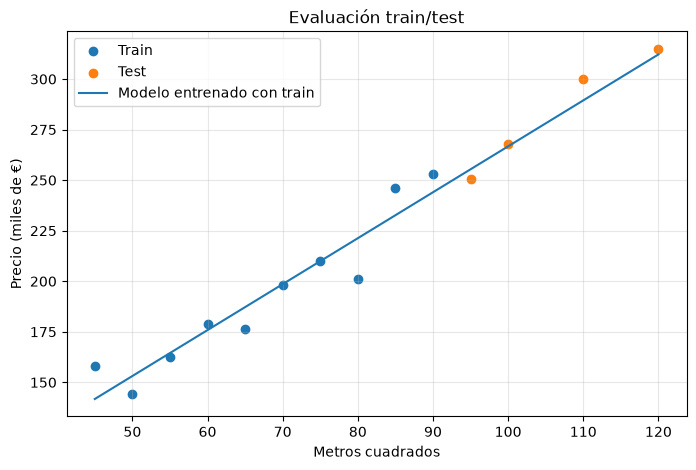

In [27]:
plt.figure(figsize=(8, 5))
plt.scatter(x_train, y_train, label="Train")
plt.scatter(x_test, y_test, label="Test")

x_line = np.linspace(m2.min(), m2.max(), 100)
y_line = pendiente_train * x_line + intercepto_train
plt.plot(x_line, y_line, label="Modelo entrenado con train")

plt.xlabel("Metros cuadrados")
plt.ylabel("Precio (miles de €)")
plt.title("Evaluación train/test")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Cómo leer la tabla train/test

No busques solo el número más bonito.

Busca coherencia:

- Si el error de train y test son parecidos, el modelo parece generalizar razonablemente.
- Si train es muy bueno y test muy malo, sospecha de overfitting.
- Si train y test son malos, sospecha de underfitting o de falta de variables relevantes.

## 20. Tabla resumen de métricas

| Sigla | English name | Nombre en español | Qué mide | Interpretación rápida |
|---|---|---|---|---|
| ME / Bias | Mean Error / Bias | Sesgo medio / error medio | Dirección media del error | Positivo: predice de más. Negativo: predice de menos. |
| MAE | Mean Absolute Error | Error absoluto medio / EAM | Error medio sin signo | Muy interpretable. Está en las unidades de la variable objetivo. |
| MSE | Mean Squared Error | Error cuadrático medio / ECM | Error medio al cuadrado | Penaliza mucho los errores grandes. Menos intuitivo por las unidades al cuadrado. |
| RMSE | Root Mean Squared Error | Raíz del error cuadrático medio | Error típico penalizando errores grandes | Está en las unidades originales. Sube mucho si hay errores grandes. |
| MAPE | Mean Absolute Percentage Error | Error porcentual absoluto medio / EPAM | Error medio porcentual | Fácil de comunicar, pero problemático con valores cercanos a cero. |
| WAPE | Weighted Absolute Percentage Error | Error porcentual absoluto ponderado | Error porcentual global | Más estable que MAPE en algunos contextos. |
| R² | R-squared / Coefficient of Determination | Coeficiente de determinación | Mejora frente a predecir la media | 1 perfecto, 0 igual que la media, negativo peor que la media. |
| Adjusted R² | Adjusted R-squared | R² ajustado | R² penalizando exceso de variables | Útil para comparar modelos con diferente número de variables. |

## 21. ¿Qué métrica debería usar?

No hay una única respuesta universal.

Depende del problema.

### Usa MAE si...

Quieres explicar el error medio de forma sencilla.

Ejemplo:

> El modelo se equivoca de media en 7.500 €.

### Usa RMSE si...

Te preocupan especialmente los errores grandes.

Ejemplo:

> En medicina, energía, logística o riesgos, un error muy grande puede ser mucho más grave que varios errores pequeños.

### Usa MAPE o WAPE si...

Quieres comunicar el error en porcentaje.

Ejemplo:

> El modelo se equivoca de media alrededor de un 6%.

Pero evita MAPE si hay valores reales cero o muy pequeños.

### Usa R² si...

Quieres saber cuánto mejora el modelo respecto a predecir siempre la media.

Pero no lo uses solo. Combínalo con MAE, RMSE y evaluación en test.

### Usa Adjusted R² si...

Quieres comparar modelos con distinto número de variables predictoras.

## 22. Mini ejercicios

### Ejercicio 1

Dado:

$$
y = [10, 20, 30]
$$

$$
\hat{y} = [12, 18, 33]
$$

Calcula:

- Bias / Mean Error
- MAE
- MSE
- RMSE
- MAPE

### Ejercicio 2

Crea dos modelos:

- Uno que siempre predice de más.
- Otro que a veces predice de más y a veces de menos.

Compara su Bias y su MAE.

### Ejercicio 3

Construye un baseline que siempre prediga la media de `precio_real` y compáralo contra la regresión lineal.

In [28]:
# Solución ejercicio 1

y_ex = np.array([10, 20, 30], dtype=float)
yhat_ex = np.array([12, 18, 33], dtype=float)

regression_metrics(y_ex, yhat_ex, p=1)

Bias / Mean Error    1.000
MAE / EAM            2.333
MSE / ECM            5.667
RMSE                 2.380
MAPE / EPAM (%)     13.333
R²                   0.915
Adjusted R²          0.830
dtype: float64

## 23. Cierre conceptual

Para evaluar una regresión, piensa en tres niveles:

### Nivel 1: dirección del error

Aquí entra:

- **Bias / Mean Error**

Pregunta:

> ¿El modelo tiende a predecir de más o de menos?

### Nivel 2: tamaño del error

Aquí entran:

- **MAE**
- **MSE**
- **RMSE**
- **MAPE**
- **WAPE**

Pregunta:

> ¿Cuánto se equivoca el modelo?

### Nivel 3: comparación contra algo básico

Aquí entra:

- **R²**
- **Adjusted R²**
- **Baseline model**

Pregunta:

> ¿Mi modelo mejora realmente a una estrategia simple como predecir siempre la media?

La evaluación completa de un modelo de regresión no consiste en memorizar fórmulas, sino en saber qué pregunta responde cada métrica.